# Model comparison

## 6.1 Compare the majority baseline, CNN, and U-Net

This notebook compares the completed validation results. The test set is reserved for final model evaluation.

In [10]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'project_plan.md').exists(): PROJECT_ROOT = PROJECT_ROOT / 'final-project'
ARTIFACT_DIR = PROJECT_ROOT / 'artifacts'
FIGURE_DIR = ARTIFACT_DIR / 'figures'
files = {
    'majority': ARTIFACT_DIR / 'MAJORITY_BASELINE_SCORES.json',
    'cnn': ARTIFACT_DIR / 'CNN_VALIDATION_SCORES.json',
    'unet': ARTIFACT_DIR / 'UNET_VALIDATION_SCORES.json',
}
missing = [path for path in files.values() if not path.exists()]
if missing: raise FileNotFoundError(f'Missing validation results: {missing}')
majority = json.loads(files['majority'].read_text(encoding='utf-8'))
cnn = json.loads(files['cnn'].read_text(encoding='utf-8'))
unet = json.loads(files['unet'].read_text(encoding='utf-8'))
comparison = pd.DataFrame([
    {'model': 'Majority baseline', 'mean_iou': majority['mean_iou'], 'weed_iou': majority['weed_iou'], 'mean_dice': sum(majority['dice']) / len(majority['dice'])},
    {'model': 'Small encoder-decoder CNN', 'mean_iou': cnn['cnn_mean_iou'], 'weed_iou': cnn['cnn_weed_iou'], 'mean_dice': cnn.get('cnn_mean_dice', float('nan'))},
    {'model': 'U-Net', 'mean_iou': unet['mean_iou'], 'weed_iou': unet['weed_iou'], 'mean_dice': sum(unet['dice']) / len(unet['dice'])},
])
comparison


,model,mean_iou,weed_iou,mean_dice
0,Majority baseline,0.323276,0.000000,0.328228
1,Small encoder-decoder CNN,0.837354,0.722102,0.907308
2,U-Net,0.850208,0.744925,0.915613


                    model  mean_iou  weed_iou  mean_dice
        Majority baseline    0.3233    0.0000     0.3282
Small encoder-decoder CNN    0.8374    0.7221     0.9073
                    U-Net    0.8502    0.7449     0.9156


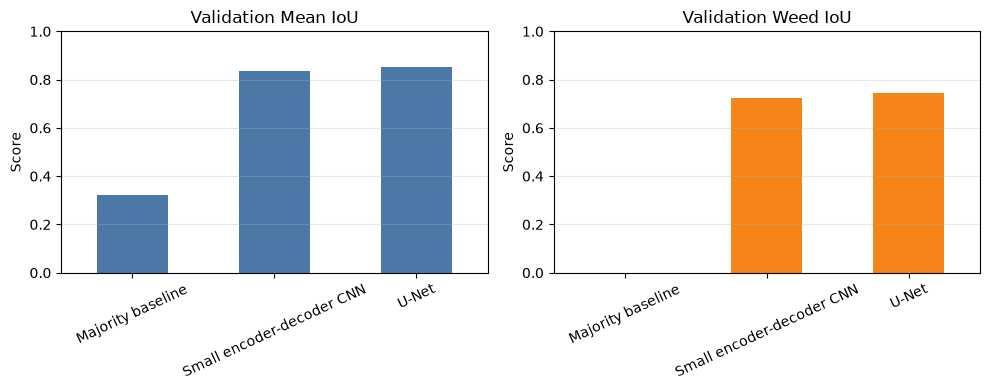

In [11]:
print(comparison.to_string(index=False, float_format=lambda value: f'{value:.4f}'))
figure, axes = plt.subplots(1, 2, figsize=(10, 4))
comparison.plot.bar(x='model', y='mean_iou', ax=axes[0], legend=False, color='#4C78A8')
comparison.plot.bar(x='model', y='weed_iou', ax=axes[1], legend=False, color='#F58518')
axes[0].set_title('Validation Mean IoU')
axes[1].set_title('Validation Weed IoU')
for axis in axes:
    axis.set_xlabel(''); axis.set_ylabel('Score'); axis.set_ylim(0, 1); axis.tick_params(axis='x', rotation=25); axis.grid(axis='y', alpha=0.3)
figure.tight_layout()
comparison.to_csv(ARTIFACT_DIR / 'MODEL_COMPARISON_VALIDATION.csv', index=False)
figure.savefig(FIGURE_DIR / 'model_comparison_validation.png', dpi=150)
plt.show()
